# OPLS-DA example using synthetic concentrations

**All observations and results in this notebook are synthetic.** This example illustrates the analysis workflow; it does not reproduce the paper's estimates or support clinical conclusions.

We compare HC with AD and HC with MCI. The second diagnosis is the positive class. As in the original analysis, we use one predictive and four orthogonal components, standard scaling, 100 stratified Monte Carlo splits, 15% test data per class, and a fixed decision threshold of 0.5. These settings are fixed for illustration, not optimized on test data.

The CSV contains 60 newly generated observations per diagnosis and only the final analysis columns: synthetic ID, diagnosis, age, and concentration predictors. Baseline selection, exclusion of gender/Tau/Glx/GSH, and the three macromolecule sums have already been applied. In particular, `M3.59.M3.90` sums M3.59, M3.71, M3.79, and M3.90. No tNAA normalization is applied: despite its filename, the original notebook does not implement that step. Age is a predictor, not an adjustment covariate.

Synthetic values were sampled jointly from a log-normal model using rounded log-scale centers, rounded pooled dispersions, a coarsened/shrunk pooled correlation matrix, and attenuated rounded diagnosis offsets. IDs and group sizes are artificial; rows were not copied or resampled. This is not a formal differential-privacy guarantee. See README for provenance and limitations.

## Setup
Run from this directory using an R Jupyter kernel. Install once in R if needed:
```r
install.packages(c("tidyverse", "pROC", "IRkernel", "BiocManager"))
BiocManager::install("ropls")
IRkernel::installspec()
```
The notebook reads only the included synthetic CSV and has no dependency on private data or `R_utils.R`. Model accessors follow the [ropls documentation](https://bioconductor.org/packages/release/bioc/vignettes/ropls/inst/doc/ropls-vignette.html).

In [1]:
library(ropls)
library(tidyverse)
library(pROC)
set.seed(20261016)
options(repr.plot.width = 10, repr.plot.height = 6)
rounds <- 100L
test_fraction <- 0.15
orthogonal_components <- 4L
# Permutations are disabled inside repeated splits for runtime. This example
# does not report permutation p-values (the original used permI = 100).
data <- read_csv("data/synthetic_concentrations_example.csv", show_col_types = FALSE)
features <- data %>% select(-c(sids, diagnose)) %>% names()
stopifnot(!anyDuplicated(data$sids), all(grepl("^SYNTH-", data$sids)),
          all(data$diagnose %in% c("HC", "MCI", "AD")),
          all(vapply(data[features], is.numeric, logical(1))),
          all(is.finite(as.matrix(data[features]))))
data %>% count(diagnose)
features

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
✖ tibble::view()  masks ropls::view()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Type 'citation("pROC")' for a citation.




Attaching package: ‘pROC’




The following objects are masked from ‘package:stats’:

    cov, smooth, var




diagnose,n
<chr>,<int>
AD,60
HC,60
MCI,60


[1] "age"         "tNAA"        "tCr"         "tCho"        "sIns"       
 [6] "mIns"        "Lac"         "Glc"         "GABA"        "Asc"        
[11] "Glu"         "Gln"         "M4.04"       "M3.21"       "M3.00"      
[16] "M2.74"       "M2.54"       "M1.70"       "M0.94"       "M1.22.M1.43"
[21] "M2.05.M2.27" "M3.59.M3.90"

## Repeated held-out evaluation
Each class is split separately, preserving class proportions. Scaling is learned by `ropls` on training data only. Every reported classification metric uses held-out predictions. Continuous regression scores are used for ROC/AUC; they need not lie in [0,1] and are not calibrated probabilities.

Sensitivity = TP/(TP+FN), specificity = TN/(TN+FP), accuracy = (TP+TN)/N, balanced accuracy = (sensitivity+specificity)/2, precision = TP/(TP+FP), and F1 = 2TP/(2TP+FP+FN). Undefined precision is recorded as NA; F1 is zero when there are positives but no positive predictions. R2X/R2Y and internal Q2 are model diagnostics, separate from held-out performance.

In [2]:
classification_metrics <- function(y, score) {
    pred <- as.integer(score > 0.5)
    tp <- sum(pred == 1 & y == 1)
    tn <- sum(pred == 0 & y == 0)
    fp <- sum(pred == 1 & y == 0)
    fn <- sum(pred == 0 & y == 1)
    sensitivity <- tp / (tp + fn)
    specificity <- tn / (tn + fp)
    c(accuracy = mean(pred == y), sensitivity = sensitivity,
      specificity = specificity, balanced_accuracy = (sensitivity + specificity) / 2,
      precision = if (tp + fp > 0) tp / (tp + fp) else NA_real_,
      F1 = 2 * tp / (2 * tp + fp + fn),
      AUC = as.numeric(pROC::auc(pROC::roc(y, score, levels = c(0, 1),
                                         direction = "<", quiet = TRUE))))
}
run_comparison <- function(data_diag, comparison, diag0, diag1) {
    d <- data_diag
    y <- d$diagnose
    x <- d %>% select(-c(sids, diagnose)) %>% as.matrix()
    metrics <- predictions <- vips <- vector("list", rounds)
    for (i in seq_len(rounds)) {
        test <- unlist(lapply(split(seq_len(nrow(d)), y), function(indices) {
            sample(indices, max(1L, ceiling(length(indices) * test_fraction)))
        }), use.names = FALSE)
        train <- setdiff(seq_len(nrow(d)), test)
        stopifnot(length(intersect(train, test)) == 0,
                  length(unique(y[test])) == 2, length(unique(y[train])) == 2)
        fit <- ropls::opls(x[train, , drop = FALSE], y[train], predI = 1,
                          orthoI = orthogonal_components, permI = 0,
                          crossvalI = 7, scaleC = "standard",
                          info.txtC = "none", fig.pdfC = "none")
        score <- as.numeric(predict(fit, x[test, , drop = FALSE]))
        stopifnot(length(score) == length(test), all(is.finite(score)))
        stats <- classification_metrics(y[test], score)
        diagnostic <- ropls::getSummaryDF(fit)
        metrics[[i]] <- as_tibble_row(as.list(stats)) %>%
            mutate(comparison = comparison, round = i, .before = 1, R2X = diagnostic[["R2X(cum)"]][1],
                                  R2Y = diagnostic[["R2Y(cum)"]][1],
                                  Q2 = diagnostic[["Q2(cum)"]][1])
        predictions[[i]] <- tibble(comparison = comparison, round = i,
            sids = d$sids[test], truth = y[test], score = score,
            predicted = as.integer(score > 0.5))
        vip <- ropls::getVipVn(fit)
        vips[[i]] <- tibble(comparison = comparison, round = i,
                               variable = names(vip), VIP = unname(vip))
    }
    # One separate full-data model for a descriptive score plot only.
    descriptive_fit <- ropls::opls(x, y, predI = 1, orthoI = orthogonal_components,
        permI = 0, scaleC = "standard", info.txtC = "none", fig.pdfC = "none")
    scores <- tibble(comparison = comparison,
        diagnosis = if_else(d$diagnose == 1, diag1, diag0),
        predictive = ropls::getScoreMN(descriptive_fit)[, 1],
        orthogonal = ropls::getScoreMN(descriptive_fit, orthoL = TRUE)[, 1])
    list(metrics = bind_rows(metrics), predictions = bind_rows(predictions),
         vip = bind_rows(vips), scores = scores)
}

## AD vs HC

In [3]:
diag0 <- "HC"
diag1 <- "AD"
comparison <- paste(diag1, "vs", diag0, sep = "_")

data_diag <- data %>%
    filter(diagnose == diag0 | diagnose == diag1) %>%
    mutate(diagnose = if_else(diagnose == diag1, 1L, 0L))

data_diag %>% count(diagnose)
results_ad_hc <- run_comparison(data_diag, comparison, diag0, diag1)

diagnose,n
<int>,<int>
0,60
1,60


## MCI vs HC

In [4]:
diag0 <- "HC"
diag1 <- "MCI"
comparison <- paste(diag1, "vs", diag0, sep = "_")

data_diag <- data %>%
    filter(diagnose == diag0 | diagnose == diag1) %>%
    mutate(diagnose = if_else(diagnose == diag1, 1L, 0L))

data_diag %>% count(diagnose)
results_mci_hc <- run_comparison(data_diag, comparison, diag0, diag1)

diagnose,n
<int>,<int>
0,60
1,60


## Combine comparisons

In [5]:
model_df_all <- bind_rows(results_ad_hc$metrics, results_mci_hc$metrics)
df_pred_all <- bind_rows(results_ad_hc$predictions, results_mci_hc$predictions)
df_vip_all <- bind_rows(results_ad_hc$vip, results_mci_hc$vip)
df_score_all <- bind_rows(results_ad_hc$scores, results_mci_hc$scores)

## Performance summaries and plots
Means and standard deviations describe split-to-split variability. Splits overlap, so these are not independent replicates and the SD is not a confidence interval. No significance tests are applied across split VIPs.

comparison,metric,mean,SD,valid_rounds
<chr>,<chr>,<dbl>,<dbl>,<int>
AD_vs_HC,AUC,0.7524691,0.10308808,100
AD_vs_HC,F1,0.6698986,0.12180313,100
AD_vs_HC,Q2,0.0661714,0.07738592,100
AD_vs_HC,R2X,0.4444200,0.01166466,100
AD_vs_HC,R2Y,0.4352900,0.02895810,100
AD_vs_HC,accuracy,0.6827778,0.11063168,100
AD_vs_HC,balanced_accuracy,0.6827778,0.11063168,100
AD_vs_HC,precision,0.7026274,0.12835054,100
AD_vs_HC,sensitivity,0.6577778,0.15846250,100


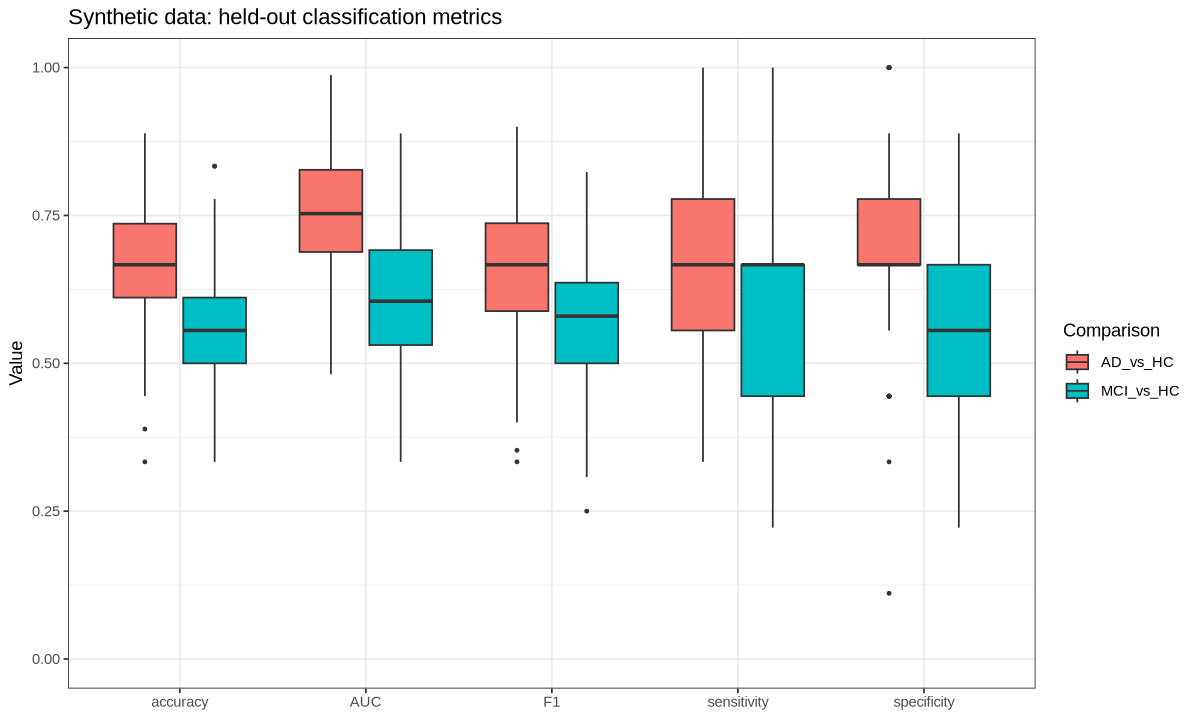

In [6]:
metric_long <- model_df_all %>%
    pivot_longer(-c(comparison, round), names_to = "metric", values_to = "value")

summary_table <- metric_long %>%
    group_by(comparison, metric) %>%
    summarize(mean = mean(value, na.rm = TRUE),
              SD = sd(value, na.rm = TRUE),
              valid_rounds = sum(is.finite(value)), .groups = "drop")
summary_table

metric_plot <- metric_long %>%
    filter(metric %in% c("F1", "specificity", "sensitivity", "accuracy", "AUC")) %>%
    ggplot(aes(x = metric, y = value, fill = comparison)) +
    geom_boxplot(outlier.size = 0.7) +
    coord_cartesian(ylim = c(0, 1)) +
    theme_bw() +
    labs(title = "Synthetic data: held-out classification metrics",
         x = NULL, y = "Value", fill = "Comparison")
metric_plot

## ROC curves from held-out subject averages
Each synthetic subject's continuous scores are averaged only over splits where that subject was held out. The AUC below summarizes these averaged scores and differs from mean split AUC. Overlapping training sets make this a descriptive cross-validation summary, not an independent external validation.

comparison,min_tests,max_tests
<chr>,<int>,<int>
AD_vs_HC,6,23
MCI_vs_HC,7,23


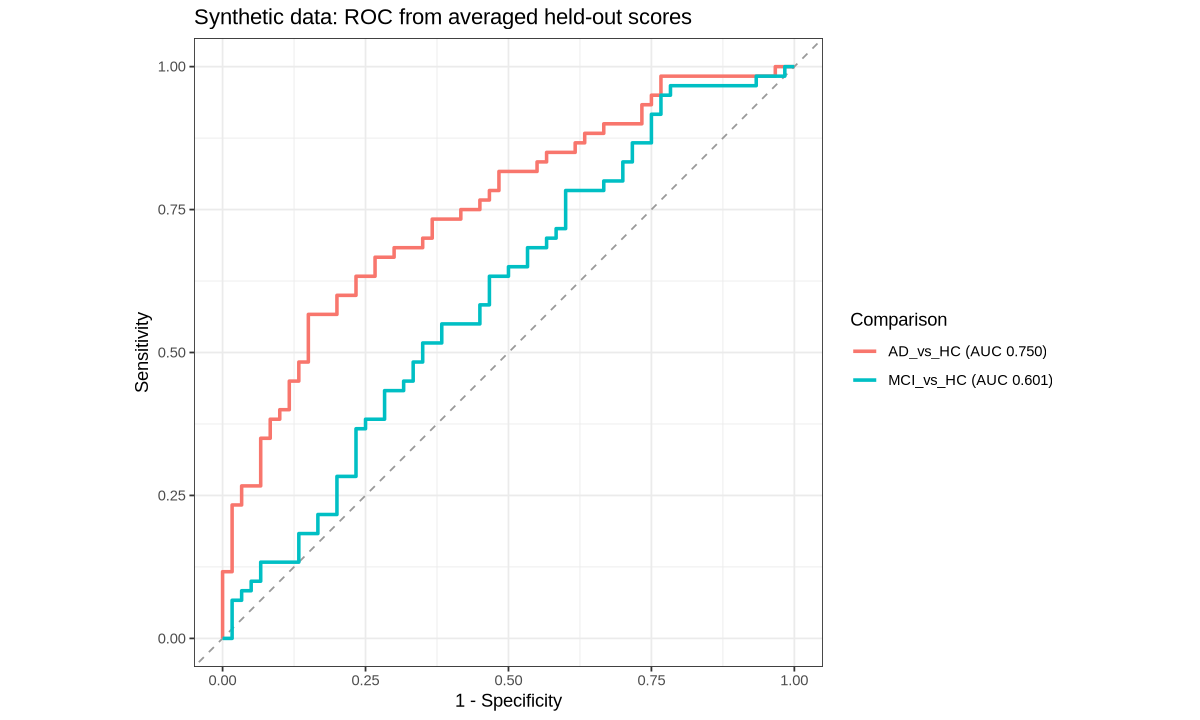

In [7]:
avg_pred_all <- df_pred_all %>%
    group_by(comparison, sids, truth) %>%
    summarize(score = mean(score), .groups = "drop")

coverage <- df_pred_all %>%
    count(comparison, sids, name = "test_appearances")
stopifnot(nrow(coverage) == nrow(df_score_all))
coverage %>%
    group_by(comparison) %>%
    summarize(min_tests = min(test_appearances), max_tests = max(test_appearances),
              .groups = "drop")

# Each ROC is computed from that comparison's averaged held-out scores.
df_roc_all <- avg_pred_all %>%
    group_by(comparison) %>%
    group_modify(~ {
        roc_curve <- pROC::roc(.x$truth, .x$score, levels = c(0, 1),
                               direction = "<", quiet = TRUE)
        tibble(FPR = 1 - roc_curve$specificities,
               TPR = roc_curve$sensitivities,
               AUC = as.numeric(pROC::auc(roc_curve)))
    }) %>%
    ungroup() %>%
    mutate(model = sprintf("%s (AUC %.3f)", comparison, AUC))

roc_plot <- df_roc_all %>%
    ggplot(aes(x = FPR, y = TPR, color = model)) +
    geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey60") +
    geom_path(linewidth = 1) +
    coord_equal() +
    theme_bw() +
    labs(title = "Synthetic data: ROC from averaged held-out scores",
         x = "1 - Specificity", y = "Sensitivity", color = "Comparison")
roc_plot

## OPLS scores and variable importance
The score plots use a separate model fitted to all synthetic observations and are **descriptive training plots**, not evidence of predictive accuracy. This avoids averaging component scores from separately fitted models, whose axes can change sign and orientation.

Predictive VIP is summarized across training fits (mean ± SD); the dashed line at one is a heuristic, not a significance threshold. All predictors, including age, are included.

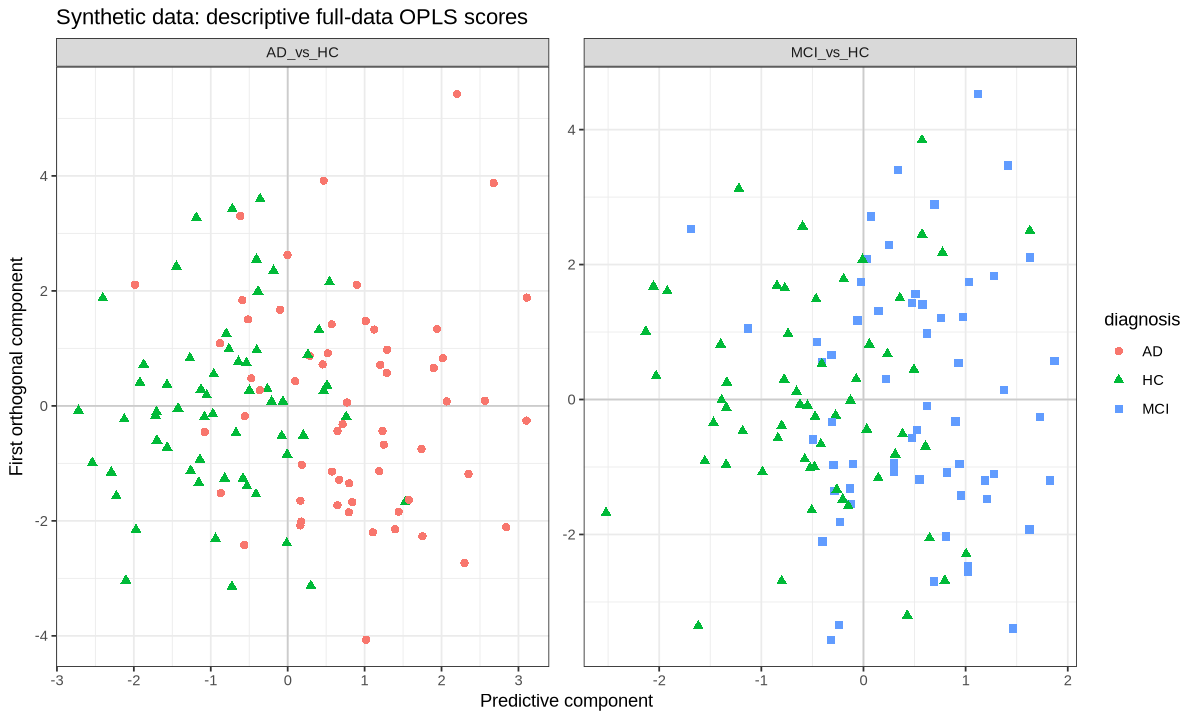

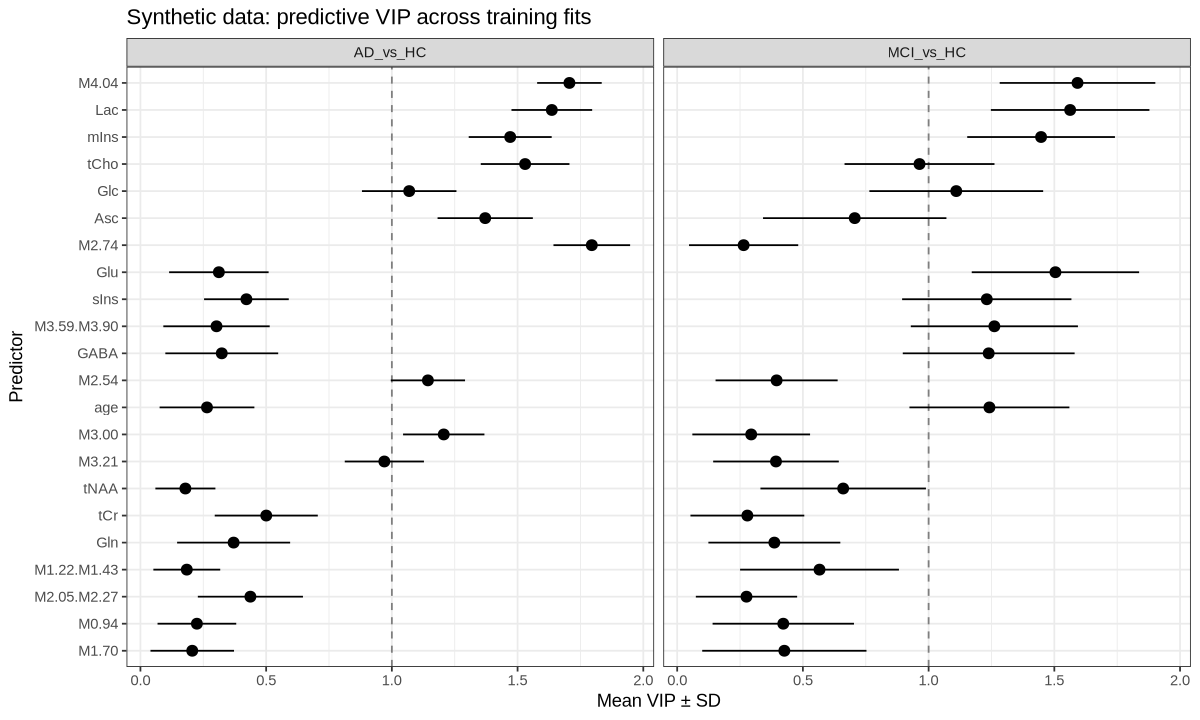

In [8]:
score_plot <- df_score_all %>%
    ggplot(aes(x = predictive, y = orthogonal, color = diagnosis, shape = diagnosis)) +
    geom_hline(yintercept = 0, color = "grey80") +
    geom_vline(xintercept = 0, color = "grey80") + geom_point(size = 2) +
    facet_wrap(~comparison, scales = "free") + theme_bw() +
    labs(title = "Synthetic data: descriptive full-data OPLS scores",
         x = "Predictive component", y = "First orthogonal component")
score_plot
vip_summary <- df_vip_all %>%
    group_by(comparison, variable) %>%
    summarize(mean = mean(VIP), SD = sd(VIP), .groups = "drop")

vip_plot <- vip_summary %>%
    ggplot(aes(x = reorder(variable, mean), y = mean)) +
    geom_hline(yintercept = 1, linetype = "dashed", color = "grey50") +
    geom_pointrange(aes(ymin = pmax(0, mean - SD), ymax = mean + SD)) +
    coord_flip() + facet_wrap(~comparison) + theme_bw() +
    labs(title = "Synthetic data: predictive VIP across training fits",
         x = "Predictor", y = "Mean VIP ± SD")
vip_plot

## Export and computational environment
All exported tables and plots are derived exclusively from the included synthetic dataset. Session information records the versions actually used.

In [9]:
dir.create("outputs", showWarnings = FALSE)
write_csv(model_df_all, "outputs/synthetic_split_metrics.csv")
write_csv(summary_table, "outputs/synthetic_metric_summary.csv")
write_csv(df_pred_all, "outputs/synthetic_held_out_predictions.csv")
write_csv(avg_pred_all, "outputs/synthetic_subject_mean_scores.csv")
write_csv(vip_summary, "outputs/synthetic_vip_summary.csv")
for (name in c("metric", "roc", "score", "vip")) {
    ggsave(file.path("outputs", paste0("synthetic_", name, ".png")),
           get(paste0(name, "_plot")), width = 10, height = 6, dpi = 150)
}
sessionInfo()

R version 4.4.2 (2024-10-31)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 26.04.1 LTS

Matrix products: default
BLAS/LAPACK: /home/orco/miniforge3/envs/R_ml/lib/libopenblasp-r0.3.29.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Europe/Berlin
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] pROC_1.18.5     lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.1   tidyverse_2.0.0 ropls_1.38.0   

loaded via a namespace (and not attached):
 [1] SummarizedExperiment_1.36.0 MultiDataSe